In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option('display.max_columns', 500)

In [2]:
data = pd.read_csv('./data/data_set.csv', delimiter=';')

In [3]:
data.head()

,AGREEMENT_RK,TARGET,AGE,SOCSTATUS_WORK_FL,SOCSTATUS_PENS_FL,GENDER,CHILD_TOTAL,DEPENDANTS,EDUCATION,MARITAL_STATUS,GEN_INDUSTRY,GEN_TITLE,ORG_TP_STATE,ORG_TP_FCAPITAL,JOB_DIR,FAMILY_INCOME,PERSONAL_INCOME,REG_ADDRESS_PROVINCE,FACT_ADDRESS_PROVINCE,POSTAL_ADDRESS_PROVINCE,TP_PROVINCE,REGION_NM,REG_FACT_FL,FACT_POST_FL,REG_POST_FL,REG_FACT_POST_FL,REG_FACT_POST_TP_FL,FL_PRESENCE_FL,OWN_AUTO,AUTO_RUS_FL,HS_PRESENCE_FL,COT_PRESENCE_FL,GAR_PRESENCE_FL,LAND_PRESENCE_FL,CREDIT,TERM,FST_PAYMENT,DL_DOCUMENT_FL,GPF_DOCUMENT_FL,FACT_LIVING_TERM,WORK_TIME,FACT_PHONE_FL,REG_PHONE_FL,GEN_PHONE_FL,LOAN_NUM_TOTAL,LOAN_NUM_CLOSED,LOAN_NUM_PAYM,LOAN_DLQ_NUM,LOAN_MAX_DLQ,LOAN_AVG_DLQ_AMT,LOAN_MAX_DLQ_AMT,PREVIOUS_CARD_NUM_UTILIZED
0,59910150,0,49,1,0,1,2,1,Среднее специальное,Состою в браке,Торговля,Рабочий,Частная компания,Без участия,Вспомогательный техперсонал,от 10000 до 20000 руб.,5000,Оренбургская область,Оренбургская область,Оренбургская область,Оренбургская область,ПОВОЛЖСКИЙ,1,1,1,1,1,0,0,0,0,0,0,0,8000,6,8650,0,1,220,18.0,0,0,1,1,1,6,2,1,1580,1580,NaN
1,59910230,0,32,1,0,1,3,3,Среднее,Состою в браке,Торговля,Рабочий,Индивидуальный предприниматель,Без участия,Участие в основ. деятельности,от 10000 до 20000 руб.,12000,Кабардино-Балкария,Кабардино-Балкария,Кабардино-Балкария,Ставропольский край,ЮЖНЫЙ,1,1,1,1,0,0,0,0,0,0,0,0,21650,6,4000,0,1,137,97.0,1,0,1,1,1,6,1,1,4020,4020,NaN
2,59910525,0,52,1,0,1,4,0,Неполное среднее,Состою в браке,Информационные технологии,Специалист,Государственная комп./учреж.,Без участия,Участие в основ. деятельности,от 10000 до 20000 руб.,9000,Иркутская область,Иркутская область,Иркутская область,Иркутская область,ВОСТОЧНО-СИБИРСКИЙ,1,1,1,1,1,0,0,0,1,0,0,0,33126,12,4000,0,1,251,84.0,0,0,1,2,1,11,0,0,0,0,NaN
3,59910803,0,39,1,0,1,1,1,Высшее,Состою в браке,Образование,Руководитель среднего звена,Государственная комп./учреж.,Без участия,Участие в основ. деятельности,от 20000 до 50000 руб.,25000,Ростовская область,Ростовская область,Ростовская область,Ростовская область,ЮЖНЫЙ,0,1,0,0,1,1,0,0,0,0,0,0,"8491,82",6,5000,0,0,36,168.0,1,1,1,1,1,6,3,1,"1589,92333333333",1590,NaN
4,59911781,0,30,1,0,0,0,0,Среднее,Состою в браке,Государственная служба,Специалист,Государственная комп./учреж.,Без участия,Участие в основ. деятельности,от 10000 до 20000 руб.,12000,Кабардино-Балкария,Кабардино-Балкария,Кабардино-Балкария,Ставропольский край,ЮЖНЫЙ,1,1,1,1,0,0,0,0,1,0,0,0,21990,12,4000,0,1,83,101.0,1,0,1,2,1,16,2,1,"1152,15",2230,NaN


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 15223 entries, 0 to 15222
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   AGREEMENT_RK                15223 non-null  int64  
 1   TARGET                      15223 non-null  int64  
 2   AGE                         15223 non-null  int64  
 3   SOCSTATUS_WORK_FL           15223 non-null  int64  
 4   SOCSTATUS_PENS_FL           15223 non-null  int64  
 5   GENDER                      15223 non-null  int64  
 6   CHILD_TOTAL                 15223 non-null  int64  
 7   DEPENDANTS                  15223 non-null  int64  
 8   EDUCATION                   15223 non-null  str    
 9   MARITAL_STATUS              15223 non-null  str    
 10  GEN_INDUSTRY                13856 non-null  str    
 11  GEN_TITLE                   13856 non-null  str    
 12  ORG_TP_STATE                13856 non-null  str    
 13  ORG_TP_FCAPITAL             13858 non-null

# Предобработка №1

Теперь сделаем простую предварительную обработку данных, а именно:

- Удалим «тяжелые» признаки ['EDUCATION', 'FACT_ADDRESS_PROVINCE', 'FAMILY_INCOME', 'GEN_INDUSTRY', 'GEN_TITLE', 'JOB_DIR', 'MARITAL_STATUS', 'ORG_TP_FCAPITAL', 'REGION_NM', 'REG_ADDRESS_PROVINCE', 'ORG_TP_STATE', 'POSTAL_ADDRESS_PROVINCE', 'TP_PROVINCE']
- Заменим запятые на точки в представлении чисел в признаках ['LOAN_AVG_DLQ_AMT', 'LOAN_AVG_DLQ_AMT']

In [5]:
def preproc(df_input):
    drop_cols = ['EDUCATION', 'FACT_ADDRESS_PROVINCE', 'FAMILY_INCOME', 'GEN_INDUSTRY', 
                 'GEN_TITLE', 'JOB_DIR', 'MARITAL_STATUS', 'ORG_TP_FCAPITAL', 'REGION_NM', 
                 'REG_ADDRESS_PROVINCE', 'ORG_TP_STATE', 'POSTAL_ADDRESS_PROVINCE', 'TP_PROVINCE', 
                 'AGREEMENT_RK']

    # Make a copy of data
    df_temp = df_input.copy()

    # Drop the hard columns
    df_temp = df_temp.drop(drop_cols, axis=1)

    digit_cols = ['LOAN_AVG_DLQ_AMT', 'LOAN_MAX_DLQ_AMT', 'CREDIT', 'FST_PAYMENT', 'PERSONAL_INCOME']
    df_temp[digit_cols] = df_temp[digit_cols].replace(regex={',': '.'}).astype('float64')

    return df_temp

In [6]:
data_preproc = preproc(data)
data_preproc.info()

<class 'pandas.DataFrame'>
RangeIndex: 15223 entries, 0 to 15222
Data columns (total 38 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   TARGET                      15223 non-null  int64  
 1   AGE                         15223 non-null  int64  
 2   SOCSTATUS_WORK_FL           15223 non-null  int64  
 3   SOCSTATUS_PENS_FL           15223 non-null  int64  
 4   GENDER                      15223 non-null  int64  
 5   CHILD_TOTAL                 15223 non-null  int64  
 6   DEPENDANTS                  15223 non-null  int64  
 7   PERSONAL_INCOME             15223 non-null  float64
 8   REG_FACT_FL                 15223 non-null  int64  
 9   FACT_POST_FL                15223 non-null  int64  
 10  REG_POST_FL                 15223 non-null  int64  
 11  REG_FACT_POST_FL            15223 non-null  int64  
 12  REG_FACT_POST_TP_FL         15223 non-null  int64  
 13  FL_PRESENCE_FL              15223 non-null

# Train / Test split

In [7]:
label_col = data_preproc.columns == 'TARGET'

# Take all columns that are not TARGET
X = data_preproc.loc[:, ~label_col].values

# Take TARGET column
y = data_preproc.loc[:, label_col].values.flatten()

In [8]:
X[:2]

array([[4.900e+01, 1.000e+00, 0.000e+00, 1.000e+00, 2.000e+00, 1.000e+00,
        5.000e+03, 1.000e+00, 1.000e+00, 1.000e+00, 1.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 8.000e+03, 6.000e+00, 8.650e+03, 0.000e+00, 1.000e+00,
        2.200e+02, 1.800e+01, 0.000e+00, 0.000e+00, 1.000e+00, 1.000e+00,
        1.000e+00, 6.000e+00, 2.000e+00, 1.000e+00, 1.580e+03, 1.580e+03,
              nan],
       [3.200e+01, 1.000e+00, 0.000e+00, 1.000e+00, 3.000e+00, 3.000e+00,
        1.200e+04, 1.000e+00, 1.000e+00, 1.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 2.165e+04, 6.000e+00, 4.000e+03, 0.000e+00, 1.000e+00,
        1.370e+02, 9.700e+01, 1.000e+00, 0.000e+00, 1.000e+00, 1.000e+00,
        1.000e+00, 6.000e+00, 1.000e+00, 1.000e+00, 4.020e+03, 4.020e+03,
              nan]])

In [9]:
y[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [10]:
from sklearn.model_selection import train_test_split

# Split data into train and test samples
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Предобработка №2

Замените пропущенные значения средними значениями признаков. Для этого нужно рассчитать средние значения для каждого входного признака, используя выборку train.

In [11]:
# Import imputer
from sklearn.impute import SimpleImputer

# Create object of the class and set up its parameters
imp = SimpleImputer(strategy='mean')

# Calculate mean values for each feature
imp.fit(X_train)

# Replace missing values in train and test samples
X_train = imp.transform(X_train)
X_test = imp.transform(X_test)

Масштабируйте входные данные с помощью StandardScaler: $$ X_{new} = \frac{X - \mu}{\sigma} $$

In [12]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create object of the class and set up its parameters
ss = StandardScaler()

# Estimate mean and sigma values
ss.fit(X_train)

# Scale train and test samples
X_train = ss.transform(X_train)
X_test = ss.transform(X_test)

# Обучение классификаторов

Cравним три классификатора:
- KNN
- Логистическая регрессия
- Древо решений

Будем использовать scikit-learn реализацию этих классификаторов

In [13]:
# Import kNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Create object of the classifier's class
knn = KNeighborsClassifier(n_neighbors=5)

# Fit the classifier
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [14]:
# Import Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier

# Create object of the classifier's class
dt = DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=None, 
                            min_samples_split=2, min_samples_leaf=10, class_weight=None)

# Fit the classifier
dt.fit(X_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

In [15]:
# Import Logistic Regression classifier
from sklearn.linear_model import LogisticRegression

# Create object of the classifier's class
logreg = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, class_weight=None)

# Fit the classifier
logreg.fit(X_train, y_train)

/home/howard/.local/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.T

# Прогнозы

Сделаем прогноз метки классов.

In [16]:
# kNN
y_test_knn = knn.predict(X_test)

# Decision Tree
y_test_dt = dt.predict(X_test)

# Logistic Regression
y_test_logreg = logreg.predict(X_test)

In [17]:
print("Truth  : ", y_test[:10])
print("kNN    : ", y_test_knn[:10])
print("DT     : ", y_test_dt[:10])
print("LogReg : ", y_test_logreg[:10])

Truth  :  [0 0 0 1 0 0 0 0 0 0]
kNN    :  [0 0 0 0 0 0 0 0 0 0]
DT     :  [0 0 0 0 0 0 0 0 0 0]
LogReg :  [0 0 0 0 0 0 0 0 0 0]


Сделаем прогноз вероятности положительного ответа клиентов.

In [18]:
# kNN
y_test_proba_knn = knn.predict_proba(X_test)[:, 1]

# Decision Tree
y_test_proba_dt = dt.predict_proba(X_test)[:, 1]

# Logistic Regression
y_test_proba_logreg = logreg.predict_proba(X_test)[:, 1]

In [19]:
print("Truth  : ", y_test[:10])
print("kNN    : ", y_test_proba_knn[:10])
print("DT     : ", y_test_proba_dt[:10])
print("LogReg : ", y_test_proba_logreg[:10])

Truth  :  [0 0 0 1 0 0 0 0 0 0]
kNN    :  [0.4 0.2 0.4 0.2 0.  0.2 0.  0.  0.  0. ]
DT     :  [0.         0.1        0.         0.         0.33333333 0.
 0.         0.         0.         0.        ]
LogReg :  [0.27965285 0.09024239 0.21916527 0.17603784 0.1414036  0.09882763
 0.08216641 0.12860752 0.16322412 0.08185794]


# Метрики качества для прогнозов меток

Матрица ошибок:

![](./img/binary_conf.png)

- TP (true positive) - currectly predicted positives
- FP (false positive) - incorrectly predicted negatives (1st order error)
- FN (false negative) - incorrectly predicted positives (2nd order error)
- TN (true negative) - currectly predicted negatives
- Pos (Neg) - total number of positives (negatives)

Quality metrics:

- $ \text{Accuracy} = \frac{TP + TN}{Pos+Neg}$
- $ \text{Error rate} = 1 -\text{accuracy}$
- $ \text{Precision} =\frac{TP}{TP + FP}$
- $ \text{Recall} =\frac{TP}{TP + FN} = \frac{TP}{Pos}$
- $ \text{F}_\beta \text{-score} = (1 + \beta^2) \cdot \frac{\mathrm{precision} \cdot \mathrm{recall}}{(\beta^2 \cdot \mathrm{precision}) + \mathrm{recall}}$

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def quality_metrics_report(y_true, y_pred):
    
    tp = np.sum( (y_true == 1) * (y_pred == 1) )
    fp = np.sum( (y_true == 0) * (y_pred == 1) )
    fn = np.sum( (y_true == 1) * (y_pred == 0) )
    tn = np.sum( (y_true == 0) * (y_pred == 0) )
    
    accuracy = accuracy_score(y_true, y_pred)
    error_rate = 1 - accuracy
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    return [tp, fp, fn, tn, accuracy, error_rate, precision, recall, f1]

In [21]:
metrics_report = pd.DataFrame(columns=['TP', 'FP', 'FN', 'TN', 'Accuracy', 'Error rate', 'Precision', 'Recall', 'F1'])

metrics_report.loc['kNN', :] = quality_metrics_report(y_test, y_test_knn)
metrics_report.loc['DT', :] = quality_metrics_report(y_test, y_test_dt)
metrics_report.loc['LogReg', :] = quality_metrics_report(y_test, y_test_logreg)

metrics_report

,TP,FP,FN,TN,Accuracy,Error rate,Precision,Recall,F1
kNN,23,70,532,3942,0.868185,0.131815,0.247312,0.041441,0.070988
DT,44,209,511,3803,0.842347,0.157653,0.173913,0.079279,0.108911
LogReg,1,3,554,4009,0.878038,0.121962,0.25,0.001802,0.003578


# Метрики качества на основе вероятностей
---
## ROC кривая

ROC кривая измеряет насколько хорошо классификатор разделяет два класса.

Пусть yi - истинная метрка и y^i - прогноз вероятности для i-го объекта.

Число положительных и отрицательных объектов: $\mathcal{I}{\rm 1} = {i: y{\rm i}=1}$ and $\mathcal{I}{\rm 0} = {i: y{\rm i}=0}$.

Для каждого порогового значения вероятности τ считаем True Positive Rate (TPR) и False Positive Rate (FPR):

\begin{equation} TPR(\tau) = \frac{1}{I_{\rm 1}} \sum_{i \in \mathcal{I}{\rm 1}} I[\hat{y}{\rm i} \ge \tau] \end{equation}

\begin{equation} FPR(\tau) = \frac{1}{I_{\rm 0}} \sum_{i \in \mathcal{I}{\rm 0}} I[\hat{y}{\rm i} \ge \tau] \end{equation}

In [22]:
from sklearn.metrics import roc_curve, auc

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_test_proba_knn)
auc_knn = auc(fpr_knn, tpr_knn)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_test_proba_dt)
auc_dt = auc(fpr_dt, tpr_dt)

fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_test_proba_logreg)
auc_logreg = auc(fpr_logreg, tpr_logreg)

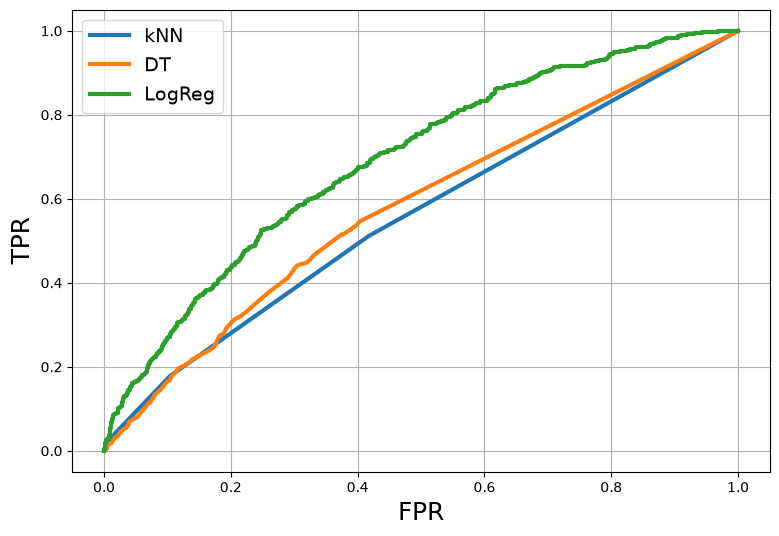

kNN ROC AUC    : 0.5581597549693262
DT ROC AUC     : 0.5792318988979008
LogReg ROC AUC : 0.6912523690190688


In [23]:
plt.figure(figsize=(9, 6))
plt.plot(fpr_knn, tpr_knn, linewidth=3, label='kNN')
plt.plot(fpr_dt, tpr_dt, linewidth=3, label='DT')
plt.plot(fpr_logreg, tpr_logreg, linewidth=3, label='LogReg')

plt.xlabel('FPR', size=18)
plt.ylabel('TPR', size=18)

plt.legend(loc='best', fontsize=14)
plt.grid()
plt.show()

print('kNN ROC AUC    :', auc_knn)
print('DT ROC AUC     :', auc_dt)
print('LogReg ROC AUC :', auc_logreg)

## Precision-Recall curve

Аналогично ROC кривой.

In [24]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_knn, recall_knn, _ = precision_recall_curve(y_test, y_test_proba_knn)
ap_knn = average_precision_score(y_test, y_test_proba_knn)

precision_dt, recall_dt, _ = precision_recall_curve(y_test, y_test_proba_dt)
ap_dt = average_precision_score(y_test, y_test_proba_dt)

precision_logreg, recall_logreg, _ = precision_recall_curve(y_test, y_test_proba_logreg)
ap_logreg = average_precision_score(y_test, y_test_proba_logreg)

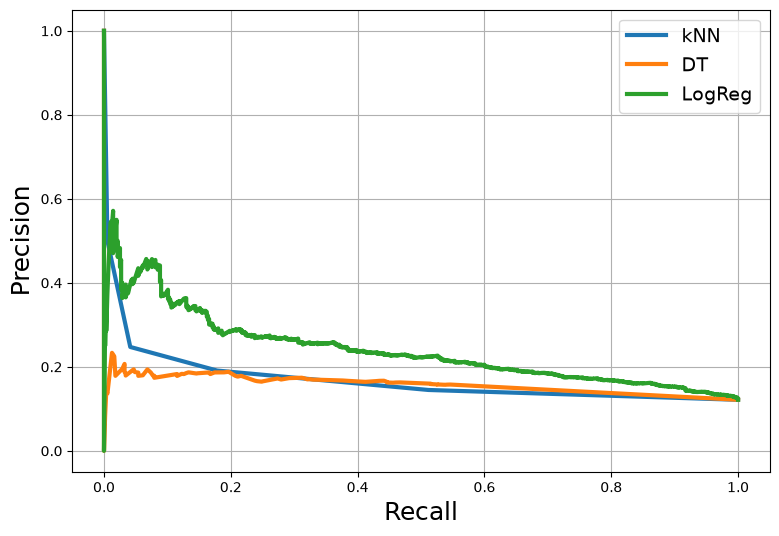

kNN AP    : 0.14542423986420286
DT AP     : 0.15015197041266168
LogReg AP : 0.23990750261891974


In [25]:
plt.figure(figsize=(9, 6))
plt.plot(recall_knn, precision_knn, linewidth=3, label='kNN')
plt.plot(recall_dt, precision_dt, linewidth=3, label='DT')
plt.plot(recall_logreg, precision_logreg, linewidth=3, label='LogReg')

plt.xlabel('Recall', size=18)
plt.ylabel('Precision', size=18)

plt.legend(loc='best', fontsize=14)
plt.grid()
plt.show()

print('kNN AP    :', ap_knn)
print('DT AP     :', ap_dt)
print('LogReg AP :', ap_logreg)

1. Какой классификатор лучше?

Лучше всех, скорее всего, окажется логистическая регрессия. Проверьте это по вашим цифрам ROC AUC и AP.

Логистическая регрессия даёт самую гладкую кривую и обычно максимальные ROC AUC и Average Precision. Её вероятности достаточно хорошо ранжируют клиентов.
Дерево при min_samples_leaf=10 переобучается, и его вероятности грубые (мало различных значений). Кривая получается ступенчатой, AUC ниже.
kNN страдает от проклятия размерности: признаков много, и многие слабо информативны. Обычно он близок к дереву или чуть лучше.

Классы в данных несбалансированы: откликов около 12%. Поэтому accuracy у всех моделей будет высокой (около 0.88), но это почти ничего не значит. Если модель всегда говорит «0», получится такой же результат. Смотрите на recall и F1 по классу 1, на ROC AUC и особенно на PR-кривую. У kNN и дерева recall по положительному классу будет очень низким.

2. Как улучшить качество моделей?

Дисбаланс классов. Использовать class_weight='balanced', оверсэмплинг (SMOTE) или андерсэмплинг. Подобрать порог вероятности под нужный баланс precision и recall.
Подбор гиперпараметров. Использовать GridSearchCV или RandomizedSearchCV с кросс-валидацией по метрике ROC AUC или AP. Для kNN подбирать n_neighbors и weights, для дерева max_depth и min_samples_leaf, для логрега C.
Признаки. Вернуть удалённые категориальные признаки через One-Hot или Target Encoding. Создать новые, например отношение кредита к доходу, и отобрать информативные. Убрать сильно коррелированные и шумовые.
Пропуски. Заполнять медианой или добавлять индикатор пропуска вместо простого среднего.
Другие модели. Random Forest, градиентный бустинг (GradientBoosting, XGBoost, LightGBM) и ансамбли обычно заметно сильнее на табличных данных.
Честная оценка. Использовать стратифицированную кросс-валидацию (StratifiedKFold) и train_test_split(..., stratify=y), чтобы доля классов сохранялась.